# LAB 2 – Khai phá dữ liệu: Bài 2 (Trang 15–16)
## Phân lớp dữ liệu Adult Income (ID3, CART, Naive Bayes)

**Sinh viên:** Nguyễn Khánh Hà – 6451071022

In [23]:
TRAIN_PATH = "adult.data.csv"   # dữ liệu huấn luyện
TEST_PATH  = "adult.test.csv"   # dữ liệu kiểm thử
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB
print("Nguyễn Khánh Hà - 6451071022")

Nguyễn Khánh Hà - 6451071022


## Câu 1: Nhập dữ liệu, cho biết số lượng dữ liệu huấn luyện và kiểm thử

In [24]:
print("Nguyễn Khánh Hà - 6451071022")
# File có header, ký hiệu dữ liệu trống là "?", sau dấu phẩy có khoảng trắng
train = pd.read_csv(TRAIN_PATH, na_values="?", skipinitialspace=True)
test = pd.read_csv(TEST_PATH, na_values="?", skipinitialspace=True)

train["income"] = train["income"].astype(str).str.strip().str.rstrip(".")
test["income"] = test["income"].astype(str).str.strip().str.rstrip(".")

print("Số lượng dữ liệu huấn luyện (adult.data):", len(train))
print("Số lượng dữ liệu kiểm thử  (adult.test):", len(test))
train.head()

Nguyễn Khánh Hà - 6451071022
Số lượng dữ liệu huấn luyện (adult.data): 32561
Số lượng dữ liệu kiểm thử  (adult.test): 16281


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Câu 2: Tiền xử lý dữ liệu


In [25]:
print("Nguyễn Khánh Hà - 6451071022")
print("Trước khi xử lý  - train:", train.shape, "| test:", test.shape)

# a) Xóa dòng có giá trị trống
train = train.dropna()
test = test.dropna()

# b) Xóa cột final weight
train = train.drop(columns="fnlwgt", errors="ignore")
test = test.drop(columns="fnlwgt", errors="ignore")

print("Sau khi xử lý    - train:", train.shape, "| test:", test.shape)

# c) Nối lại
n_train = len(train)
full = pd.concat([train, test], ignore_index=True)
print("Sau khi nối      - full:", full.shape)
full.head()

Nguyễn Khánh Hà - 6451071022
Trước khi xử lý  - train: (32561, 15) | test: (16281, 14)
Sau khi xử lý    - train: (30162, 14) | test: (15060, 14)
Sau khi nối      - full: (45222, 14)


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng hệ số Pearson
Cột nào có giá trị tương đồng cao (|r| > 0.8) thì loại bỏ.

Nguyễn Khánh Hà - 6451071022
                 age  education-num  capital-gain  capital-loss  \
age             1.00           0.04          0.08          0.06   
education-num   0.04           1.00          0.13          0.08   
capital-gain    0.08           0.13          1.00         -0.03   
capital-loss    0.06           0.08         -0.03          1.00   
hours-per-week  0.10           0.15          0.08          0.05   

                hours-per-week  
age                       0.10  
education-num             0.15  
capital-gain              0.08  
capital-loss              0.05  
hours-per-week            1.00  


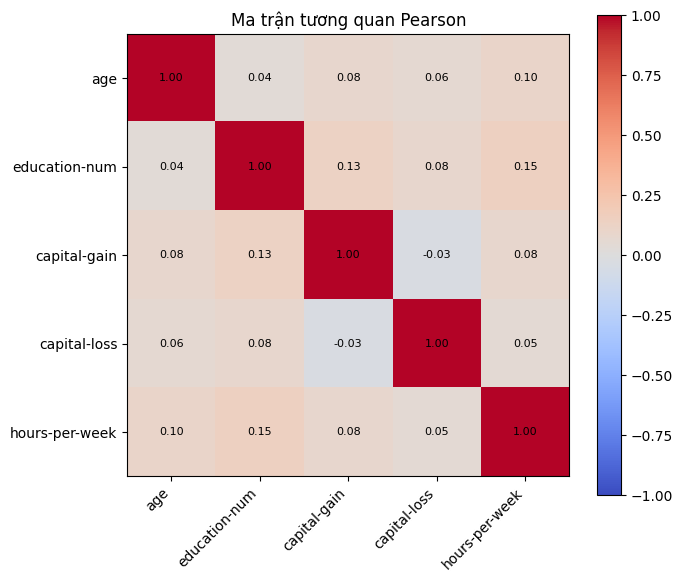


Các cột có |r| > 0.8 cần loại bỏ: không có
Kích thước dữ liệu sau khi loại: (45222, 14)


In [26]:
print("Nguyễn Khánh Hà - 6451071022")
THRESHOLD = 0.8
num_cols = full.select_dtypes(include="number").columns
corr = full[num_cols].corr(method="pearson")
print(corr.round(2))

# Heatmap
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Ma trận tương quan Pearson")
plt.tight_layout()
plt.show()

# Tìm cột có tương quan cao với một cột đứng trước nó
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > THRESHOLD).any()]
print(f"\nCác cột có |r| > {THRESHOLD} cần loại bỏ:", to_drop if to_drop else "không có")
full = full.drop(columns=to_drop)
print("Kích thước dữ liệu sau khi loại:", full.shape)

## Câu 4: Tách dữ liệu thành thuộc tính bình thường và thuộc tính quyết định

In [27]:
print("Nguyễn Khánh Hà - 6451071022")
X = full.drop(columns="income")   # thuộc tính bình thường
y = full["income"]                # thuộc tính quyết định
print("X:", X.shape, "| y:", y.shape)
print(y.value_counts())
X.head()

Nguyễn Khánh Hà - 6451071022
X: (45222, 13) | y: (45222,)
income
<=50K    34014
>50K     11208
Name: count, dtype: int64


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


## Câu 5: Chuyển các cột không phải dạng số về one-hot vector

In [28]:
print("Nguyễn Khánh Hà - 6451071022")
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Các cột dạng chữ:", cat_cols)
print("Số cột trước khi one-hot:", X.shape[1])

X = pd.get_dummies(X, columns=cat_cols, dtype=int)
y = (y == ">50K").astype(int)     # 1: >50K (lớp dương), 0: <=50K

print("Số cột sau khi one-hot  :", X.shape[1])
X.head()

Nguyễn Khánh Hà - 6451071022
Các cột dạng chữ: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Số cột trước khi one-hot: 13
Số cột sau khi one-hot  : 103


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


## Câu 6: Tách dữ liệu thành hai phần huấn luyện và kiểm thử như ban đầu

In [29]:
print("Nguyễn Khánh Hà - 6451071022")
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)

Nguyễn Khánh Hà - 6451071022
X_train: (30162, 103) | y_train: (30162,)
X_test : (15060, 103) | y_test : (15060,)


## Câu 7: Xây dựng cây ID3 (criterion = entropy), ma trận nhầm lẫn và biểu diễn cây

Nguyễn Khánh Hà - 6451071022
Classification report - ID3:

              precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.63      0.61      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.81      0.82      0.81     15060

Confusion matrix:
 [[10026  1334]
 [ 1441  2259]]


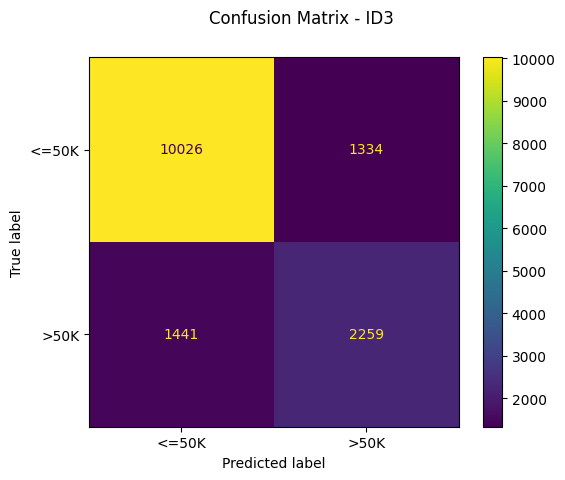

In [30]:
print("Nguyễn Khánh Hà - 6451071022")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
id3.fit(X_train, y_train)
pred_id3 = id3.predict(X_test)

print("Classification report - ID3:\n")
print(metrics.classification_report(y_test, pred_id3, target_names=["<=50K", ">50K"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(id3, X_test, y_test, display_labels=["<=50K", ">50K"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - ID3")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


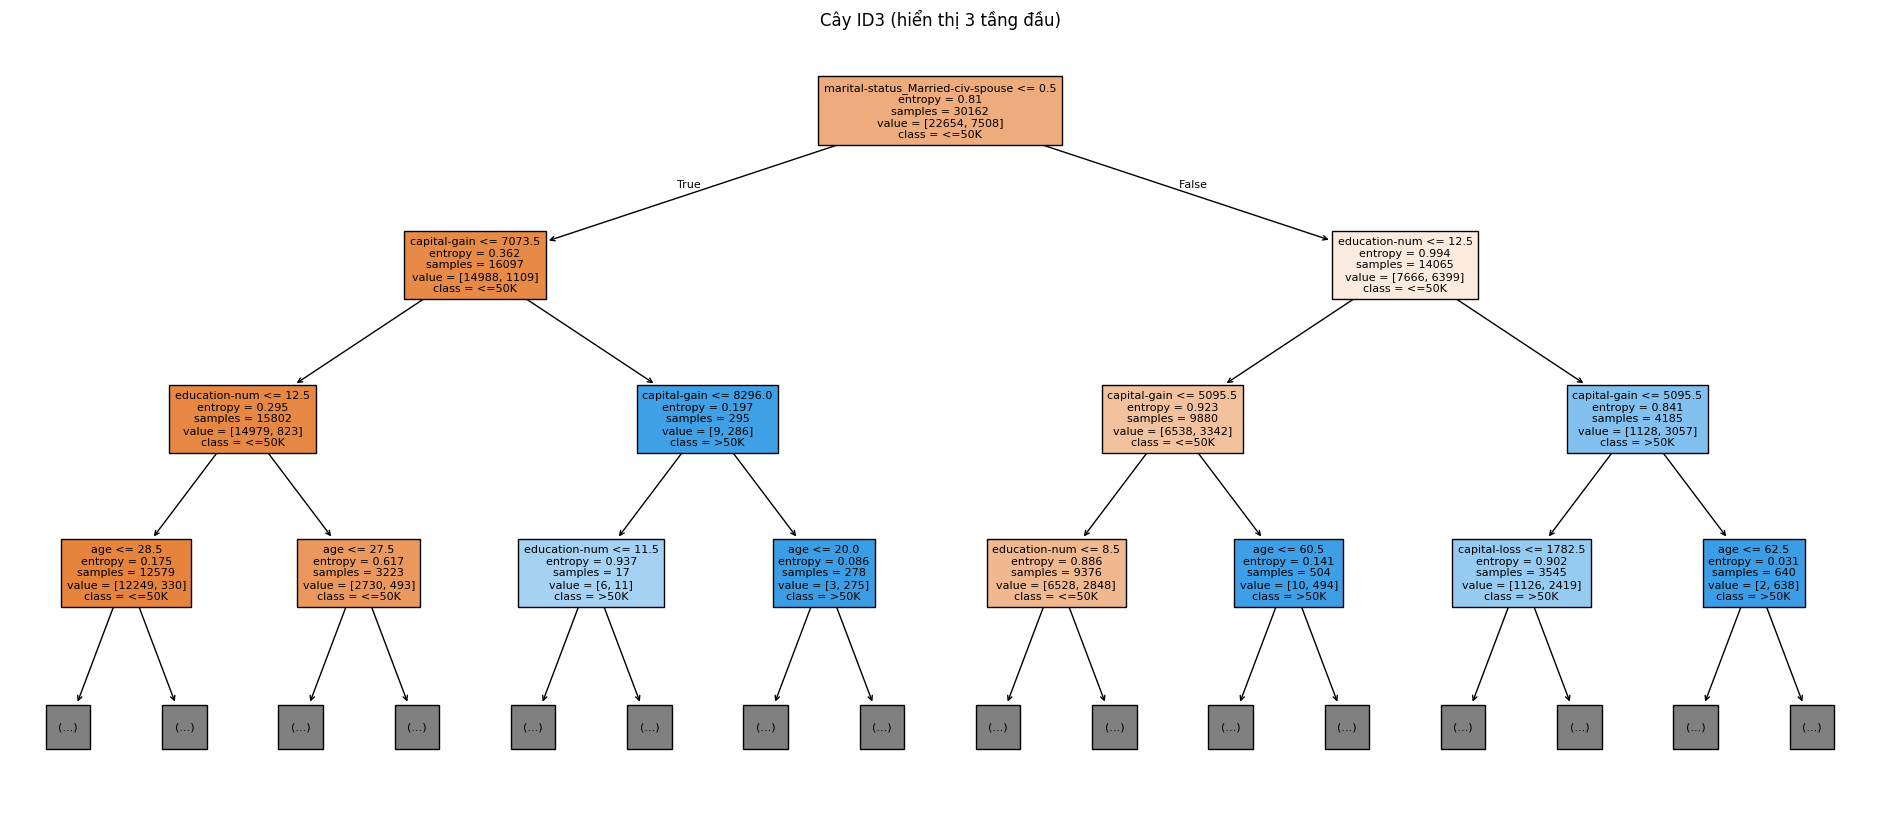

Độ sâu thực tế của cây: 54 | Số lá: 5321


In [31]:
print("Nguyễn Khánh Hà - 6451071022")
plt.figure(figsize=(24, 10))
tree.plot_tree(id3, max_depth=3, feature_names=X.columns, class_names=["<=50K", ">50K"],
               filled=True, fontsize=8)
plt.title("Cây ID3 (hiển thị 3 tầng đầu)")
plt.show()
print("Độ sâu thực tế của cây:", id3.get_depth(), "| Số lá:", id3.get_n_leaves())

## Câu 8: Lặp lại Câu 7 với cây CART (criterion = gini)

Nguyễn Khánh Hà - 6451071022
Classification report - CART:

              precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.75     15060
weighted avg       0.81      0.81      0.81     15060

Confusion matrix:
 [[10006  1354]
 [ 1463  2237]]


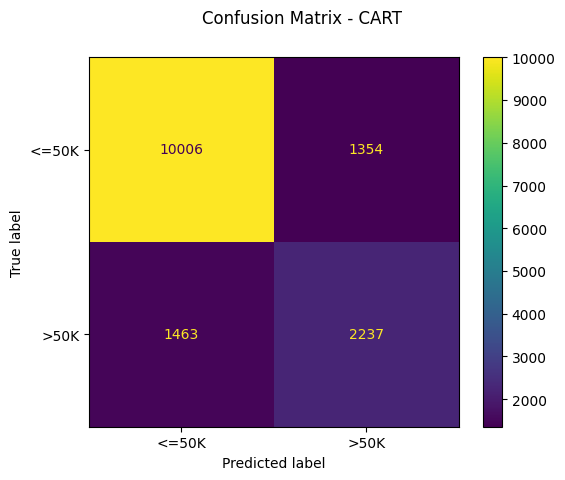

In [32]:
print("Nguyễn Khánh Hà - 6451071022")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
cart.fit(X_train, y_train)
pred_cart = cart.predict(X_test)

print("Classification report - CART:\n")
print(metrics.classification_report(y_test, pred_cart, target_names=["<=50K", ">50K"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(cart, X_test, y_test, display_labels=["<=50K", ">50K"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - CART")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

Nguyễn Khánh Hà - 6451071022


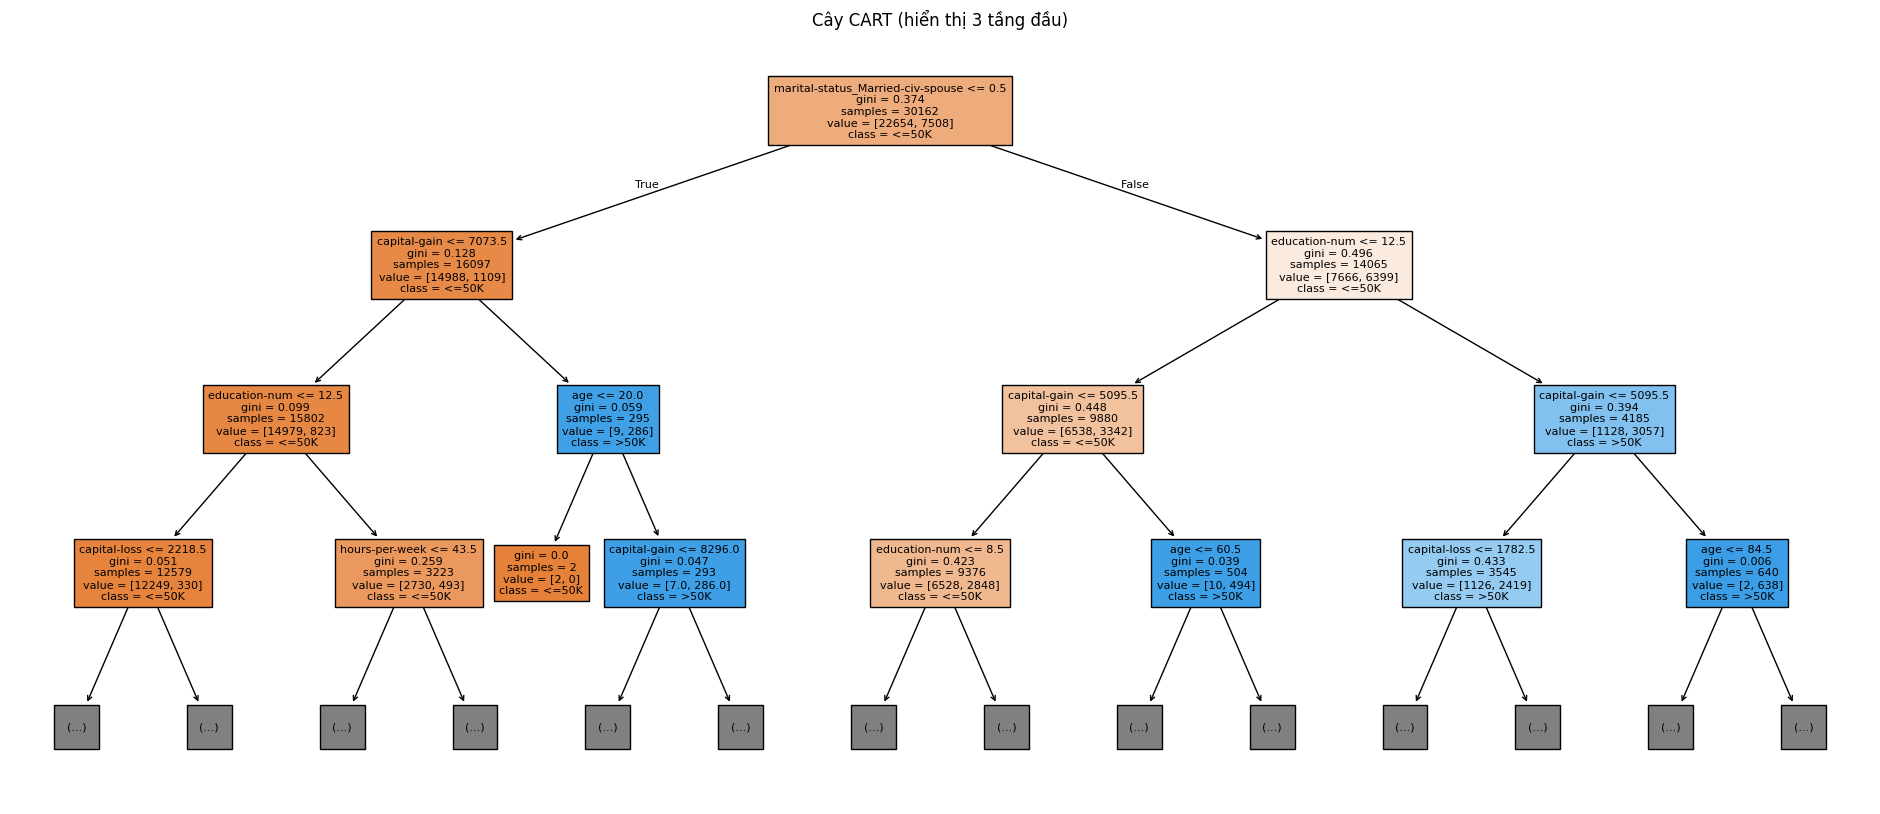

Độ sâu thực tế của cây: 46 | Số lá: 5344


In [33]:
print("Nguyễn Khánh Hà - 6451071022")
plt.figure(figsize=(24, 10))
tree.plot_tree(cart, max_depth=3, feature_names=X.columns, class_names=["<=50K", ">50K"],
               filled=True, fontsize=8)
plt.title("Cây CART (hiển thị 3 tầng đầu)")
plt.show()
print("Độ sâu thực tế của cây:", cart.get_depth(), "| Số lá:", cart.get_n_leaves())

## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả

Nguyễn Khánh Hà - 6451071022
Classification report - Naïve Bayes:

              precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060

Confusion matrix:
 [[9073 2287]
 [ 681 3019]]


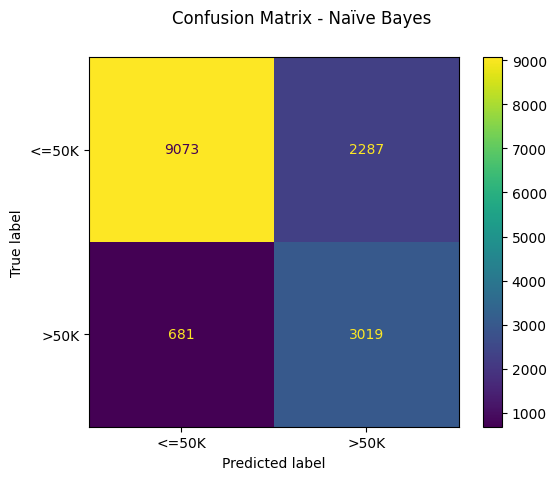

In [34]:
print("Nguyễn Khánh Hà - 6451071022")
nb = GaussianNB()
nb.fit(X_train, y_train)
pred_nb = nb.predict(X_test)

print("Classification report - Naïve Bayes:\n")
print(metrics.classification_report(y_test, pred_nb, target_names=["<=50K", ">50K"]))
disp = metrics.ConfusionMatrixDisplay.from_estimator(nb, X_test, y_test, display_labels=["<=50K", ">50K"], values_format="d")
disp.figure_.suptitle("Confusion Matrix - Naïve Bayes")
print("Confusion matrix:\n", disp.confusion_matrix)
plt.show()

## Câu 10: So sánh kết quả của các mô hình
Lớp dương là `>50K`.

Nguyễn Khánh Hà - 6451071022
             Accuracy  Precision  Recall  F-measure
Mô hình                                            
ID3            0.8157     0.6287  0.6105     0.6195
CART           0.8129     0.6229  0.6046     0.6136
Naive Bayes    0.8029     0.5690  0.8159     0.6704


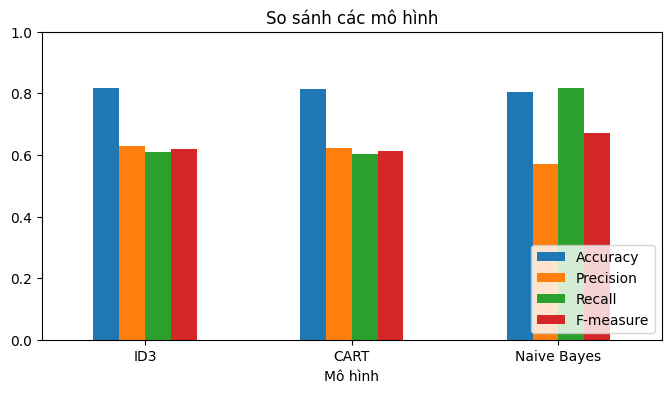


=> Mô hình có Accuracy cao nhất: ID3 (0.8157)


In [35]:
print("Nguyễn Khánh Hà - 6451071022")
preds = {"ID3": pred_id3, "CART": pred_cart, "Naive Bayes": pred_nb}
rows = []
for name, p in preds.items():
    rows.append({
        "Mô hình": name,
        "Accuracy":  metrics.accuracy_score(y_test, p),
        "Precision": metrics.precision_score(y_test, p),
        "Recall":    metrics.recall_score(y_test, p),
        "F-measure": metrics.f1_score(y_test, p),
    })
result = pd.DataFrame(rows).set_index("Mô hình").round(4)
print(result)

result.plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("So sánh các mô hình"); plt.ylim(0, 1); plt.legend(loc="lower right")
plt.show()

best = result["Accuracy"].idxmax()
print(f"\n=> Mô hình có Accuracy cao nhất: {best} ({result.loc[best, 'Accuracy']:.4f})")

**Nhận xét:** ID3 có accuracy cao nhất (0.8157), nhỉnh hơn CART (0.8129) và Naïve Bayes (0.8029). Naïve Bayes có precision thấp nhất (0.569) nhưng recall cao nhất (0.816), nghĩa là bắt được nhiều người thu nhập >50K hơn (chỉ bỏ sót 681 người so với 1441 của ID3), đổi lại dự đoán nhầm nhiều hơn (2287 so với 1334). Vì vậy Naïve Bayes có F-measure cao nhất (0.670). Nếu ưu tiên độ chính xác tổng thể thì chọn ID3, nếu ưu tiên không bỏ sót lớp >50K thì chọn Naïve Bayes.